# Day 17 — Machine Learning Algorithms
**Internship:** Data Analytics / Data Science  
**Deliverable:** Executable Jupyter notebook  
**Models:** Linear Regression, Decision Tree Regressor, Logistic Regression, Random Forest Classifier, K-Means  
**Data:** Three clearly labeled *synthetic demonstration datasets*, provided alongside this notebook. Not actual customer, property or company records.

**Institute requirement:** Train at least 2 regression, 2 classification, and 1 clustering models.  
**Reproducibility:** Fixed random seeds, test splits, explicit preprocessing.

## 1. Setup and dataset overview
Install dependencies using `python -m pip install -r requirements.txt` in the VS Code terminal. Run cells from top to bottom. The CSV files must be in the same directory as the notebook.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, silhouette_score)
DATA_DIR = Path.cwd()
print('Working directory:', DATA_DIR)
print('Libraries imported successfully')

Working directory: e:\Internship\Assignment Completed\Day and Task 17\Day17_ML_Algorithms_Complete_Package\Day17_ML_Algorithms
Libraries imported successfully


## 2. Regression — predict a numerical house price
Features: area, bedrooms, property age and distance to city center. Target: `Price_INR`. Split before fitting; compare both models on the *same held-out test set*.

In [16]:
houses = pd.read_csv(DATA_DIR / 'house_prices_synthetic.csv')
print('Dataset shape:', houses.shape)
display(houses.head())
print('Missing values:', houses.isna().sum().sum())
X_reg = houses.drop(columns=['Price_INR'])
y_reg = houses['Price_INR']
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42)
reg_models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree Regressor': DecisionTreeRegressor(max_depth=5, min_samples_leaf=5, random_state=42)
}
reg_results = []
reg_predictions = {}
for name, model in reg_models.items():
    model.fit(X_reg_train, y_reg_train)
    predicted = model.predict(X_reg_test)
    reg_predictions[name] = predicted
    reg_results.append({'Model': name,
                        'MAE_INR': mean_absolute_error(y_reg_test, predicted),
                        'RMSE_INR': np.sqrt(mean_squared_error(y_reg_test, predicted)),
                        'R2': r2_score(y_reg_test, predicted)})
reg_comparison = pd.DataFrame(reg_results).round(3)
display(reg_comparison)

Dataset shape: (360, 5)


,Area_sqft,Bedrooms,Property_Age_Years,Distance_to_Center_km,Price_INR
0,2191,2,5,15.02,9982440
1,2435,3,5,18.91,12086427
2,702,1,27,14.75,1753712
3,828,2,4,10.57,4697339
4,1526,3,14,8.88,8080722


Missing values: 0


,Model,MAE_INR,RMSE_INR,R2
0,Linear Regression,542276.408,696872.957,0.960
1,Decision Tree Regressor,665151.370,819515.408,0.944


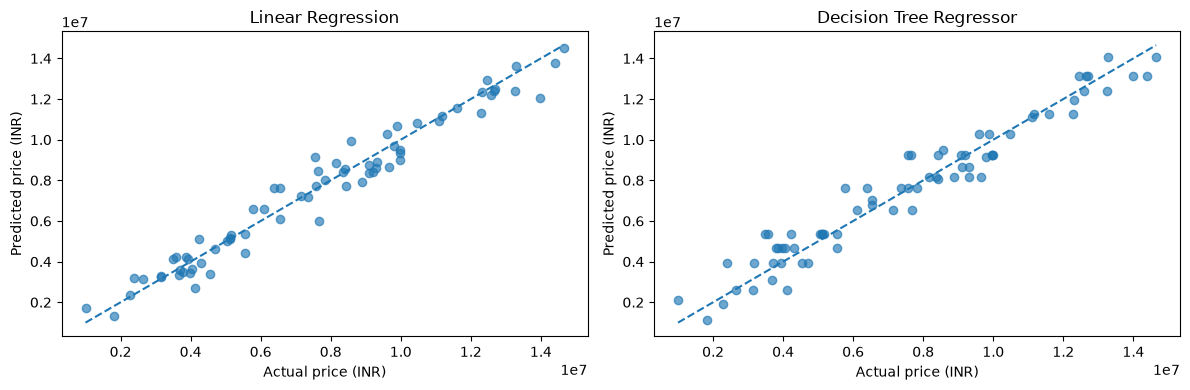

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, predictions) in zip(axes, reg_predictions.items()):
    ax.scatter(y_reg_test, predictions, alpha=0.65)
    low = min(y_reg_test.min(), predictions.min())
    high = max(y_reg_test.max(), predictions.max())
    ax.plot([low, high], [low, high], '--')
    ax.set(title=name, xlabel='Actual price (INR)', ylabel='Predicted price (INR)')
plt.tight_layout()
plt.show()

**Interpretation:** Lower MAE/RMSE and higher R² are generally preferable on the same test data. These values describe only this synthetic dataset, not real housing-market performance.

## 3. Classification — predict customer churn
Features: tenure, monthly charges, support calls, annual contract, satisfaction. Target: `Churn` (1 = yes, 0 = no). Stratified split maintains the approximate churn proportion. Scaling is fitted *only on training data* inside the Logistic Regression pipeline.

In [18]:
customers = pd.read_csv(DATA_DIR / 'customer_churn_synthetic.csv')
print('Dataset shape:', customers.shape)
display(customers.head())
print('Churn class distribution:')
display(customers['Churn'].value_counts())
X_clf = customers.drop(columns=['Churn'])
y_clf = customers['Churn']
X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=42, stratify=y_clf)
clf_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    'Random Forest Classifier': RandomForestClassifier(n_estimators=150, max_depth=7,
                                                        min_samples_leaf=3, random_state=42)
}
clf_results = []
clf_predictions = {}
for name, model in clf_models.items():
    model.fit(X_clf_train, y_clf_train)
    predicted = model.predict(X_clf_test)
    clf_predictions[name] = predicted
    clf_results.append({'Model': name,
                        'Accuracy': accuracy_score(y_clf_test, predicted),
                        'Precision': precision_score(y_clf_test, predicted, zero_division=0),
                        'Recall': recall_score(y_clf_test, predicted, zero_division=0),
                        'F1': f1_score(y_clf_test, predicted, zero_division=0)})
clf_comparison = pd.DataFrame(clf_results).round(3)
display(clf_comparison)

Dataset shape: (500, 6)


,Tenure_Months,Monthly_Charges_INR,Support_Calls_90_Days,Annual_Contract,Satisfaction_Score,Churn
0,36,860.06,2,0,1,1
1,48,2309.90,0,0,1,1
2,42,2386.31,3,1,2,1
3,62,1316.80,4,0,2,1
4,7,907.97,3,0,2,0


Churn class distribution:


Churn
1    276
0    224
Name: count, dtype: int64

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.64,0.667,0.691,0.679
1,Random Forest Classifier,0.63,0.655,0.691,0.673


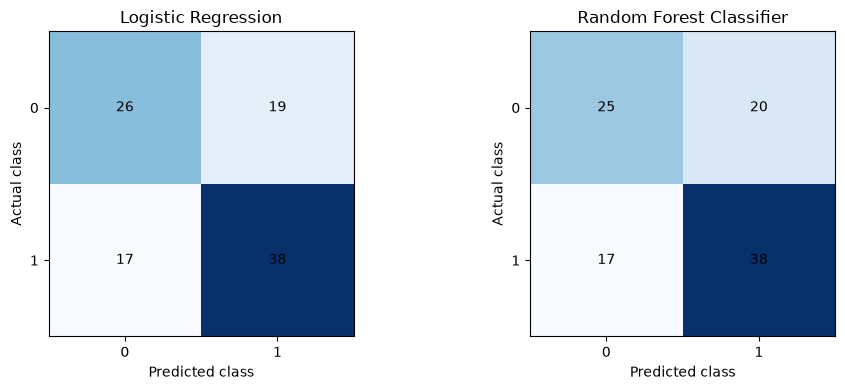

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, predicted) in zip(axes, clf_predictions.items()):
    matrix = confusion_matrix(y_clf_test, predicted, labels=[0, 1])
    ax.imshow(matrix, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, matrix[i, j], ha='center', va='center')
    ax.set(title=name, xlabel='Predicted class', ylabel='Actual class',
           xticks=[0, 1], yticks=[0, 1])
plt.tight_layout()
plt.show()

**Interpretation:** Accuracy alone can hide poor churn detection when classes are imbalanced. Check precision, recall, F1, and confusion matrices. Day 18 will study evaluation metrics in greater depth.

## 4. Clustering — K-Means customer segmentation
Features: annual spend and annual order count. There is **no target variable**. Standardize both columns before clustering because they use different units. Fit K-Means with 3 clusters; these are exploratory groupings, not known customer labels.

In [20]:
segments = pd.read_csv(DATA_DIR / 'customer_segments_synthetic.csv')
display(segments.head())
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(segments)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
segments['Cluster'] = kmeans.fit_predict(X_cluster_scaled)
print('Silhouette score:', round(silhouette_score(X_cluster_scaled, segments['Cluster']), 3))
print('Cluster sizes:')
display(segments['Cluster'].value_counts().sort_index())
print('Cluster profile (mean values):')
display(segments.groupby('Cluster')[['Annual_Spend_INR', 'Orders_Per_Year']].mean().round(1))

,Annual_Spend_INR,Orders_Per_Year
0,4519.0,9
1,1342.0,3
2,6253.0,9
3,8207.0,19
4,1443.0,4


Silhouette score: 0.73
Cluster sizes:


Cluster
0    120
1    120
2    120
Name: count, dtype: int64

Cluster profile (mean values):


,Annual_Spend_INR,Orders_Per_Year
Cluster,,
0,8048.4,17.2
1,1261.3,3.0
2,4521.7,8.8


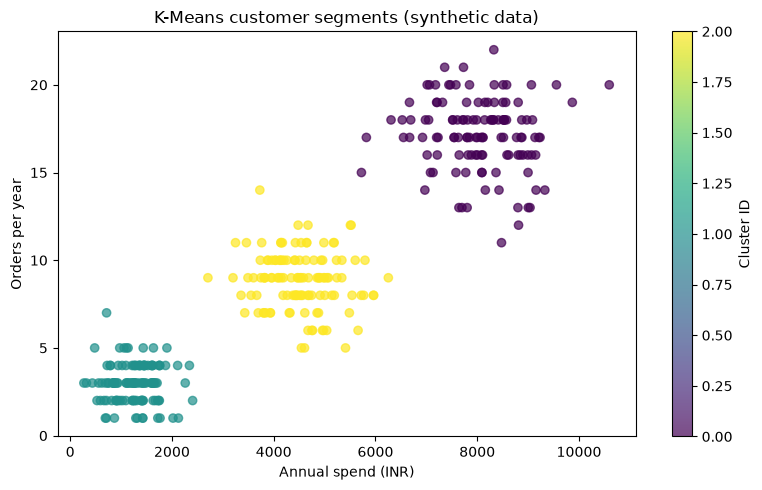

In [21]:
plt.figure(figsize=(8, 5))
plt.scatter(segments['Annual_Spend_INR'], segments['Orders_Per_Year'],
            c=segments['Cluster'], cmap='viridis', alpha=0.7)
plt.xlabel('Annual spend (INR)')
plt.ylabel('Orders per year')
plt.title('K-Means customer segments (synthetic data)')
plt.colorbar(label='Cluster ID')
plt.tight_layout()
plt.show()

## 5. Summary and conclusions
- **Regression (2 models):** Linear Regression and Decision Tree Regressor predict numeric house prices.
- **Classification (2 models):** Logistic Regression and Random Forest Classifier predict churn labels.
- **Clustering (1 model):** K-Means finds three customer groups without predefined labels.
- **Best model selection:** Compare models on held-out data and business costs; a single score is not sufficient.
- **Limitations:** All datasets are synthetic for learning. Model performance cannot be generalized to real organizations without validation on representative real data.

**Submission screenshots:** notebook execution, regression comparison and chart, classification comparison and confusion matrices, K-Means plot, and final summary.